# NNHẬP DỮ LIỆU VÀ TIỀN XỬ LÝ DỮ LIỆU

In [4]:
print("NguyenDucTinh - 6451071077")

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

# Đọc file dữ liệu nấm
data = pd.read_csv('mushrooms.csv')

# Kiểm tra số lượng dữ liệu ban đầu
print("Số lượng dữ liệu ban đầu:", len(data))

# Xóa các dòng chứa dữ liệu trống (nếu có ký hiệu '?' hoặc NaN)
data = data.replace('?', np.nan).dropna()

# Kiểm tra lại cấu trúc dữ liệu
data.info()


NguyenDucTinh - 6451071077
Số lượng dữ liệu ban đầu: 8124
<class 'pandas.DataFrame'>
Index: 5644 entries, 0 to 8114
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     5644 non-null   str  
 1   cap-shape                 5644 non-null   str  
 2   cap-surface               5644 non-null   str  
 3   cap-color                 5644 non-null   str  
 4   bruises                   5644 non-null   str  
 5   odor                      5644 non-null   str  
 6   gill-attachment           5644 non-null   str  
 7   gill-spacing              5644 non-null   str  
 8   gill-size                 5644 non-null   str  
 9   gill-color                5644 non-null   str  
 10  stalk-shape               5644 non-null   str  
 11  stalk-root                5644 non-null   str  
 12  stalk-surface-above-ring  5644 non-null   str  
 13  stalk-surface-below-ring  5644 non-null   str  
 14

# CÂU 4: TÁCH FEATURES VÀ LABELS

In [5]:
print("NguyenDucTinh - 6451071077")

# Tách features (thuộc tính bình thường) và labels (thuộc tính quyết định 'class')
features = data.drop('class', axis=1)
labels = data['class']

NguyenDucTinh - 6451071077


# CÂU 5: CHUYỂN ĐỔI ONE-HOT VECTOR

In [6]:
print("NguyenDucTinh - 6451071077")

# Xác định các cột dạng chữ/phân loại
non_numeric_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Các cột dạng chữ:", non_numeric_cols)

# Chuyển đổi về dạng one-hot vector (ép kiểu int để hiển thị 0/1)
features_onehot = pd.get_dummies(features, columns=non_numeric_cols, dtype=int)
features_onehot

NguyenDucTinh - 6451071077
Các cột dạng chữ: Index(['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat'],
      dtype='str')


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_n,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u
0,0,0,0,0,0,1,0,0,1,0,...,0,1,0,0,0,0,0,0,0,1
1,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,1,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,1,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,1,0,0,0,1,...,0,1,0,0,0,0,0,0,0,1
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7986,1,0,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0
8001,0,0,0,0,0,1,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0
8038,0,0,0,0,0,1,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0
8095,0,0,0,0,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0


# CÂU 6: TÁCH DỮ LIỆU HUẤN LUYỆN VÀ KIỂM THỬ

In [7]:
print("NguyenDucTinh - 6451071077")

X = features_onehot
y = labels

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Số lượng dữ liệu huấn luyện (X_train):", len(X_train))
print("Số lượng dữ liệu kiểm thử (X_test):", len(X_test))

NguyenDucTinh - 6451071077
Số lượng dữ liệu huấn luyện (X_train): 3950
Số lượng dữ liệu kiểm thử (X_test): 1694


# CÂU 7: XÂY DỰNG CÂY QUYẾT ĐỊNH ID3

NguyenDucTinh - 6451071077
Accuracy (ID3): 1.0
Report (ID3):
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1058
           p       1.00      1.00      1.00       636

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694



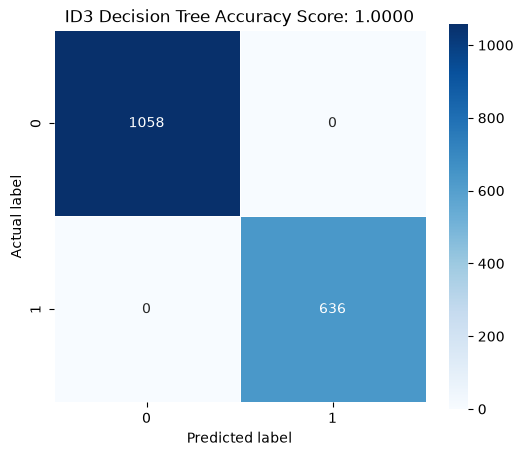

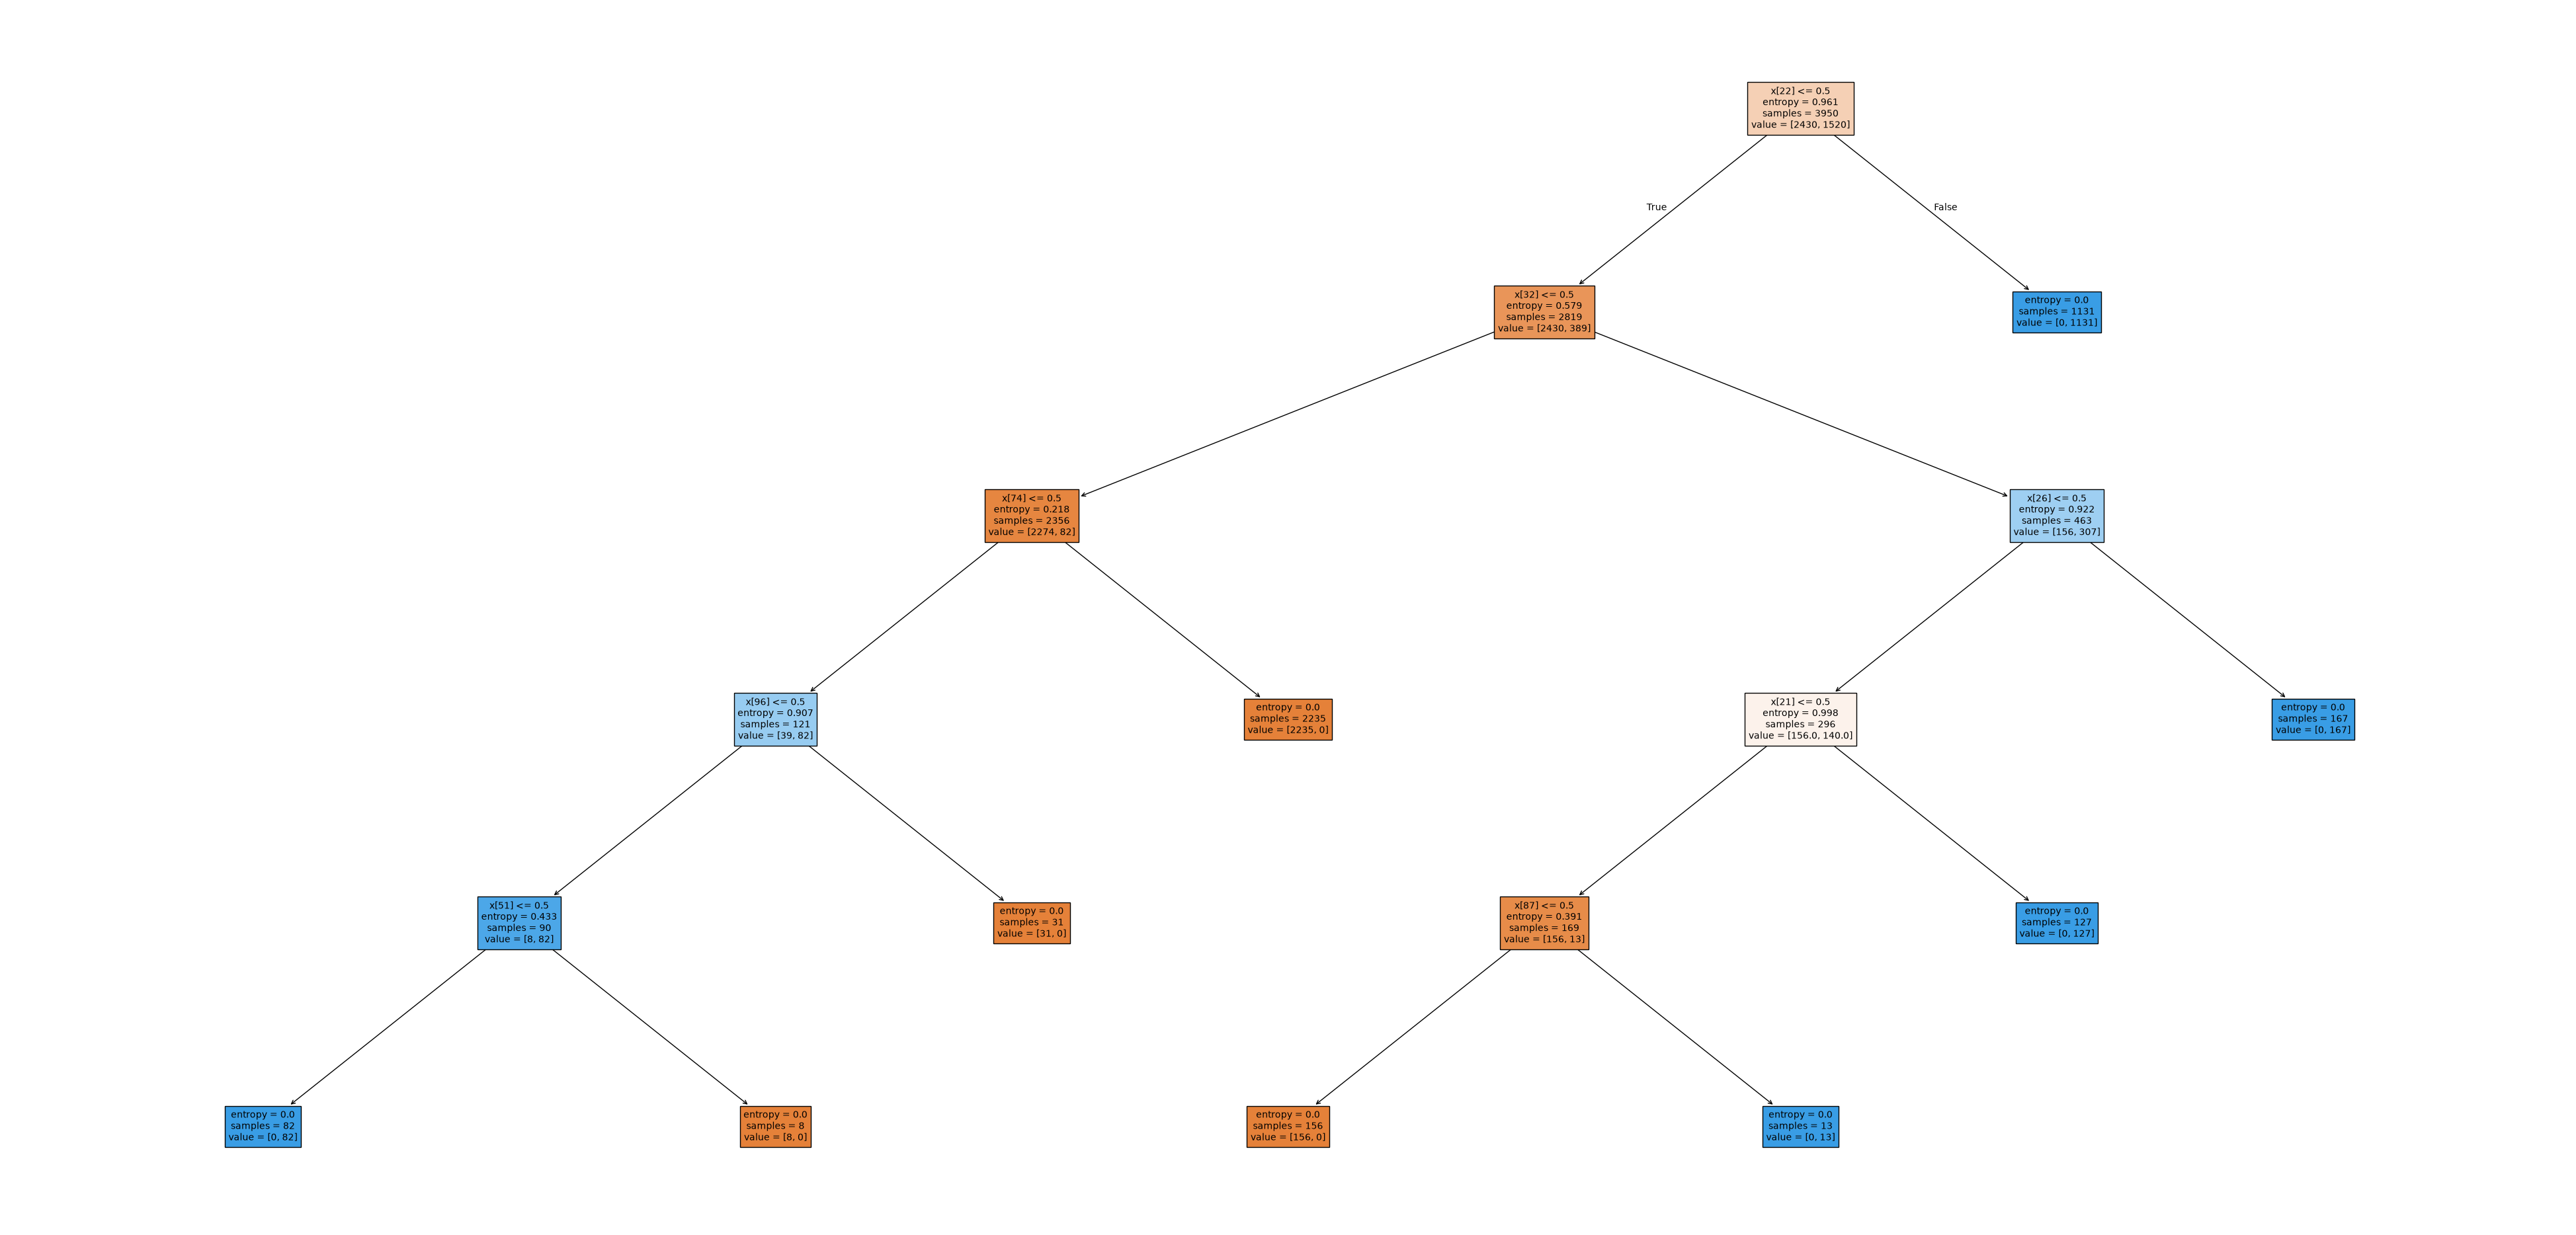

In [8]:
print("NguyenDucTinh - 6451071077")

# Huấn luyện mô hình Cây quyết định ID3 (criterion='entropy')
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
clf_id3.fit(X_train, y_train)

# Dự đoán và đánh giá
id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)

print("Accuracy (ID3):", id3_score)
print("Report (ID3):\n", metrics.classification_report(y_test, id3_pred))

# Vẽ ma trận nhầm lẫn (Confusion Matrix)
id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'ID3 Decision Tree Accuracy Score: {id3_score:.4f}', size=12)
plt.show()

# Biểu diễn và lưu cấu trúc cây quyết định
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_id3, filled=True, fontsize=10)
plt.savefig('decision_tree_ID3.png', dpi=100)
plt.show()

# CÂU 8: XÂY DỰNG CÂY QUYẾT ĐỊNH CART

NguyenDucTinh - 6451071077
Accuracy (CART): 1.0
Report (CART):
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1058
           p       1.00      1.00      1.00       636

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694



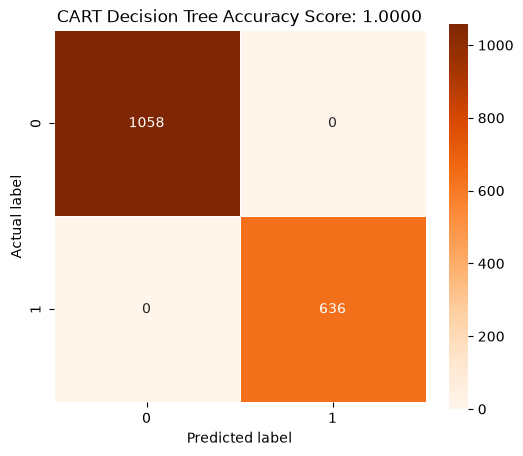

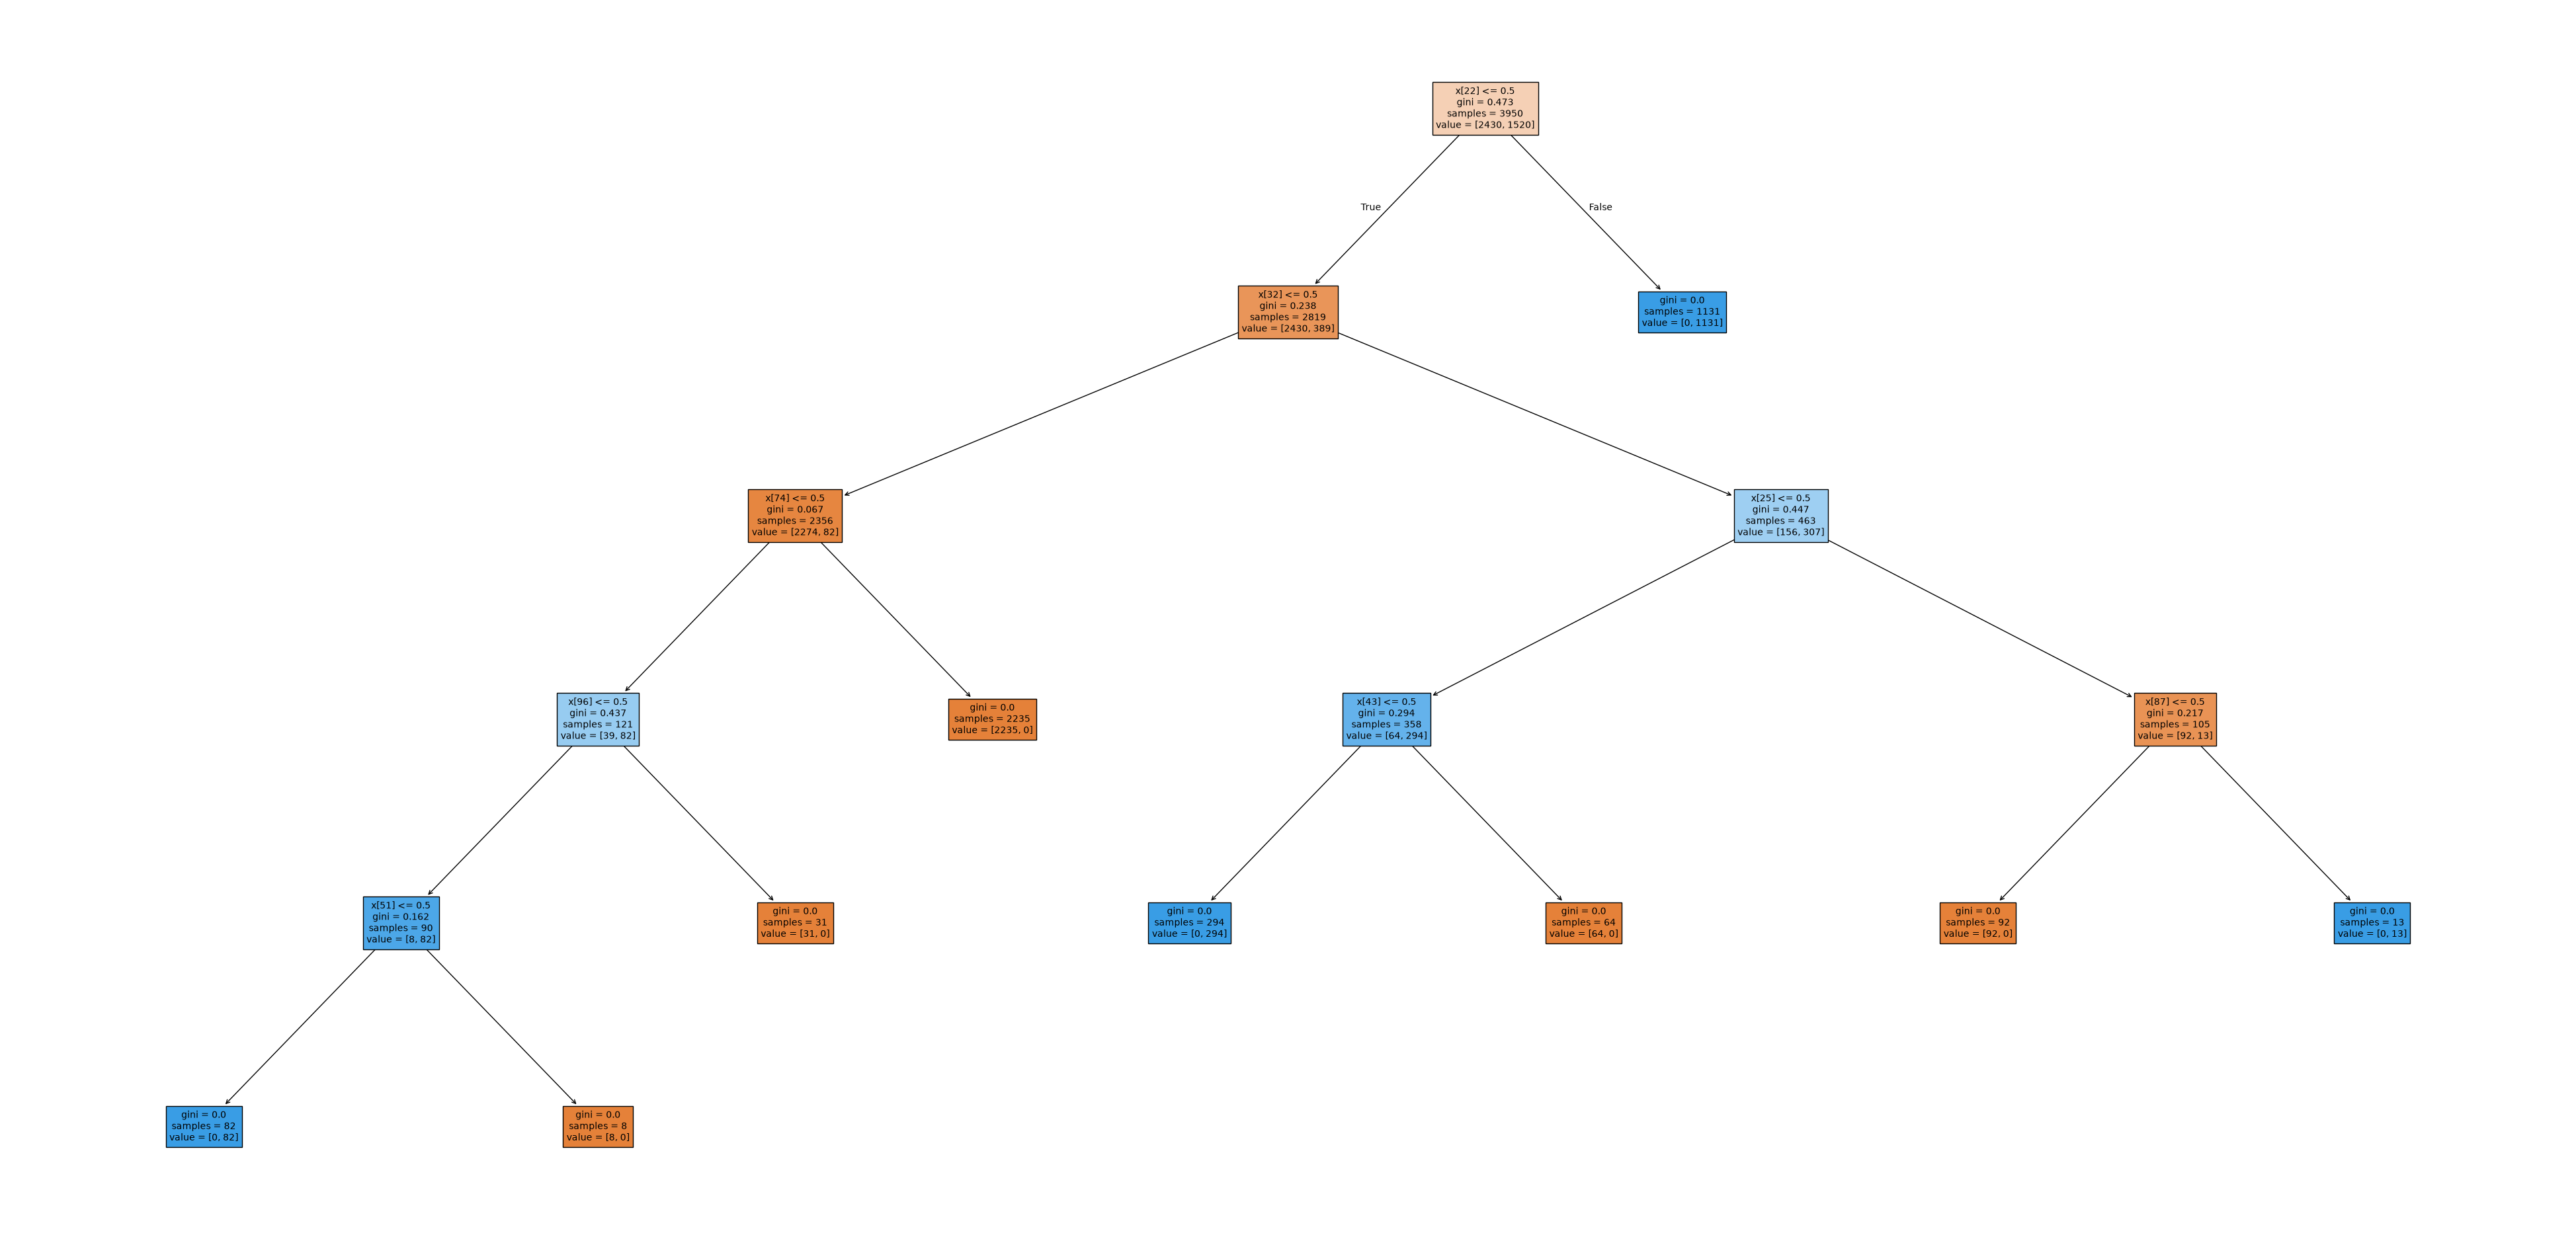

In [9]:
print("NguyenDucTinh - 6451071077")

# Huấn luyện mô hình Cây quyết định CART (criterion='gini')
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
clf_cart.fit(X_train, y_train)

# Dự đoán và đánh giá
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print("Accuracy (CART):", cart_score)
print("Report (CART):\n", metrics.classification_report(y_test, cart_pred))

# Vẽ ma trận nhầm lẫn cho CART
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Oranges')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'CART Decision Tree Accuracy Score: {cart_score:.4f}', size=12)
plt.show()

# Biểu diễn và lưu cấu trúc cây quyết định CART
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_cart, filled=True, fontsize=10)
plt.savefig('decision_tree_CART.png', dpi=100)
plt.show()

# CÂU 9: XÂY DỰNG MÔ HÌNH NAIVE BAYES

NguyenDucTinh - 6451071077
Accuracy (Naïve Bayes): 0.9976387249114522
Report (Naïve Bayes):
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1058
           p       0.99      1.00      1.00       636

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694



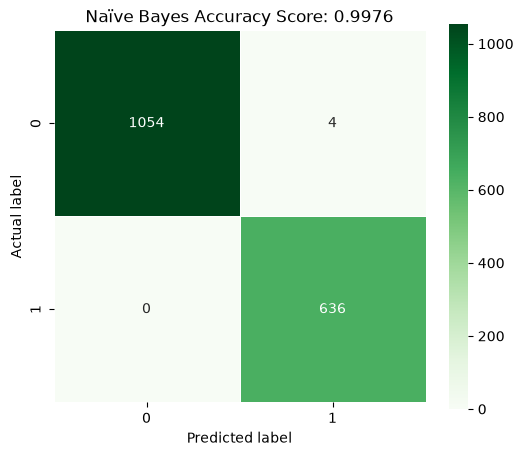

In [10]:
print("NguyenDucTinh - 6451071077")

# Huấn luyện mô hình Naïve Bayes
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)

print("Accuracy (Naïve Bayes):", bayes_score)
print("Report (Naïve Bayes):\n", metrics.classification_report(y_test, bayes_pred))

# Vẽ ma trận nhầm lẫn cho Naïve Bayes
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naïve Bayes Accuracy Score: {bayes_score:.4f}', size=12)
plt.show()